# Game of Life: CPU (C) vs GPU (CUDA)

Compares a C CPU version with two CUDA versions (naive and tiled), checks that all give the same result, and makes charts and GIFs.

## Overview

| Item | Value |
|---|---|
| Grid | 2048 x 2048, wrap-around edges |
| Generations | 100 |
| Start state | ~30 % live cells, same seed in both programs |
| CPU | C, 2D arrays, `gcc -O2 -falign-loops=64`, 1 thread |
| GPU | CUDA, 1 thread per cell, 16 x 16 blocks, naive + tiled kernels |
| Timing | CPU: `clock_gettime`. GPU: CUDA events (kernel time and total with copies) |

## Requirements

| Need | Notes |
|---|---|
| Linux + `gcc` | for the CPU program |
| NVIDIA GPU + `nvcc` | turn on a GPU in the notebook settings |
| Python packages | `numpy`, `matplotlib`, `Pillow` |

## How to run

| Step | What to do |
|---|---|
| 1 | Run all cells from top to bottom (about 1-2 minutes) |
| 2 | Don't run anything else during Section 4 (it measures time) |

## Sections

| # | Section | What it does |
|---|---|---|
| 1 | Environment | Shows CPU, GPU, compiler info |
| 2 | Source files | Writes the C and CUDA programs |
| 3 | Build | Compiles both |
| 4 | Benchmarks | Times CPU and GPU (no other work runs here) |
| 5 | Results | Speedup table and chart |
| 6 | Verification | Checks CPU and GPU results match |
| 7 | Animation | Saves frames and makes GIFs |
| 8 | Summary | Final summary and JSON file |

## Output files

| File | Content |
|---|---|
| `benchmark_runs.csv` | Every timed run |
| `comparison.png` | Time chart and GPU breakdown |
| `frame_cpu.pgm`, `frame_cuda.pgm` | Final grid from each program |
| `frames_cpu/`, `frames_cuda/` | Animation frames |
| `life_*.gif` | CPU, GPU and side-by-side animations |
| `results_summary.json` | Timings, speedups, verification |

## Configuration

Settings used by later cells. `N` and `ITERS` must match the `#define` values in the C/CUDA code.

| Setting | Meaning |
|---|---|
| `RUNS` | Timed runs per program |
| `WARMUP` | Untimed runs before timing |
| `FRAME_EVERY` | Save a frame every this many generations |
| `GIF_SIZE` | GIF frame size (px) |
| `GIF_MS` | Time per GIF frame (ms) |

In [4]:
N, ITERS    = 2048, 100     # must match the sources
RUNS        = 5
WARMUP      = 1
FRAME_EVERY = 2
GIF_SIZE    = 512
GIF_MS      = 120

## 1. Environment

Prints the CPU, GPU and compiler info. Stops if no GPU is found.

In [5]:
import subprocess, os, re, json, csv, glob, filecmp, hashlib, statistics as st

def sh(cmd, hint=""):
    """Run a shell command, return stdout, raise with a clear message on failure."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}\n{r.stdout}{r.stderr}\n{hint}")
    return r.stdout

cpu_model = sh("lscpu | grep 'Model name'").split(":", 1)[1].strip()
cpu_cores = sh("nproc").strip()
gcc_ver   = sh("gcc --version | head -n 1").strip()

no_gpu = "No NVIDIA GPU or CUDA toolkit found. Enable a GPU accelerator for this session and restart."
gpu_line = sh("nvidia-smi --query-gpu=name,compute_cap,memory.total,driver_version --format=csv,noheader",
              no_gpu).splitlines()[0]
gpu_name, gpu_cc, gpu_mem, gpu_driver = [x.strip() for x in gpu_line.split(",")]
nvcc_ver = sh("nvcc --version | grep release", no_gpu).strip()
ARCH = "sm_" + gpu_cc.replace(".", "")

print(f"CPU      : {cpu_model} ({cpu_cores} logical CPUs)")
print(f"Compiler : {gcc_ver}")
print(f"GPU      : {gpu_name}, compute capability {gpu_cc}, {gpu_mem}, driver {gpu_driver}")
print(f"CUDA     : {nvcc_ver}")
print(f"nvcc arch: {ARCH}")

CPU      : Intel(R) Xeon(R) CPU @ 2.00GHz (4 logical CPUs)
Compiler : gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
GPU      : Tesla T4, compute capability 7.5, 15360 MiB, driver 580.178.04
CUDA     : Cuda compilation tools, release 12.8, V12.8.93
nvcc arch: sm_75


## 2. Source files

### 2.1 CPU program (`life_cpu.c`)

Plain C version. Modes: no argument = time it, `save` = also save the final grid, `frames [k]` = save animation frames (not timed).

`step()` is marked `noinline` and `restrict`, and the build uses `-falign-loops=64`, so the CPU time stays low and consistent.

In [6]:
%%writefile life_cpu.c
/*
 * Conway's Game of Life - CPU version (2D arrays)
 * High Performance Computing Assignment
 *
 * Grid : 2048 x 2048, toroidal (wrap-around) boundaries
 * Steps: 100 iterations
 * Build: gcc -O2 -falign-loops=64 -o life_cpu life_cpu.c
 * Run  : ./life_cpu          (timing only)
 *        ./life_cpu save     (also writes the final grid to frame_cpu.pgm)
 *        ./life_cpu frames [k]  (animation mode, NOT timed: writes the top-left
 *                            CROP x CROP corner every k generations, default 2,
 *                            to frames_cpu/frame_GGGG.pgm)
 */
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <time.h>
#include <sys/stat.h>

#define N     2048      /* grid is N x N */
#define ITERS 100
#define SEED  12345u
#define CROP  256       /* size of the corner written in frames mode */

/* Deterministic per-cell hash, identical in the CUDA program,
   so both versions start from the same grid and can be cross-checked. */
static unsigned char init_cell(int r, int c)
{
    unsigned int x = (unsigned int)(r * N + c) ^ SEED;
    x ^= x >> 16; x *= 0x7feb352dU;
    x ^= x >> 15; x *= 0x846ca68bU;
    x ^= x >> 16;
    return (x % 100u) < 30u;           /* ~30% of cells start alive */
}

static double now_ms(void)
{
    struct timespec t;
    clock_gettime(CLOCK_MONOTONIC, &t);
    return t.tv_sec * 1000.0 + t.tv_nsec / 1e6;
}

/* noinline: step() stays a separate function, so the timing does not depend on the
   other code in the file. restrict: cur and nxt never overlap. */
static __attribute__((noinline))
void step(unsigned char (*restrict cur)[N], unsigned char (*restrict nxt)[N])
{
    for (int r = 0; r < N; r++) {
        int up = (r == 0)     ? N - 1 : r - 1;
        int dn = (r == N - 1) ? 0     : r + 1;
        for (int c = 0; c < N; c++) {
            int lf = (c == 0)     ? N - 1 : c - 1;
            int rt = (c == N - 1) ? 0     : c + 1;

            int n = cur[up][lf] + cur[up][c] + cur[up][rt]
                  + cur[r][lf]               + cur[r][rt]
                  + cur[dn][lf] + cur[dn][c] + cur[dn][rt];

            nxt[r][c] = (n == 3) || (cur[r][c] && n == 2);
        }
    }
}

/* Write the grid as a binary PGM image: live = white (255), dead = black (0). */
static void save_pgm(const char *path, const unsigned char *g)
{
    FILE *f = fopen(path, "wb");
    if (!f) { fprintf(stderr, "cannot open %s\n", path); return; }
    fprintf(f, "P5\n%d %d\n255\n", N, N);
    unsigned char *buf = (unsigned char *)malloc((size_t)N * N);
    for (size_t i = 0; i < (size_t)N * N; i++) buf[i] = g[i] ? 255 : 0;
    fwrite(buf, 1, (size_t)N * N, f);
    free(buf);
    fclose(f);
}

/* Write only the top-left CROP x CROP corner (used for the animation frames). */
static void save_crop(const char *path, const unsigned char *g)
{
    FILE *f = fopen(path, "wb");
    if (!f) { fprintf(stderr, "cannot open %s\n", path); return; }
    fprintf(f, "P5\n%d %d\n255\n", CROP, CROP);
    for (int r = 0; r < CROP; r++)
        for (int c = 0; c < CROP; c++)
            fputc(g[(size_t)r * N + c] ? 255 : 0, f);
    fclose(f);
}

static long count_alive(unsigned char (*g)[N])
{
    long s = 0;
    for (int r = 0; r < N; r++)
        for (int c = 0; c < N; c++) s += g[r][c];
    return s;
}

int main(int argc, char **argv)
{
    unsigned char (*a)[N] = malloc(sizeof(unsigned char[N][N]));
    unsigned char (*b)[N] = malloc(sizeof(unsigned char[N][N]));
    if (!a || !b) { fprintf(stderr, "malloc failed\n"); return 1; }

    for (int r = 0; r < N; r++)
        for (int c = 0; c < N; c++) a[r][c] = init_cell(r, c);

    printf("Game of Life - CPU (2D arrays)\n");
    printf("Grid: %d x %d  Iterations: %d\n", N, N, ITERS);
    printf("Initial alive cells: %ld\n", count_alive(a));

    /* Animation mode: dump frames, no timing, then exit. */
    if (argc > 1 && strcmp(argv[1], "frames") == 0) {
        int every = (argc > 2) ? atoi(argv[2]) : 2;
        if (every < 1) every = 1;
        mkdir("frames_cpu", 0777);
        for (int g = 0; g <= ITERS; g++) {
            if (g % every == 0) {
                char name[64];
                snprintf(name, sizeof name, "frames_cpu/frame_%04d.pgm", g);
                save_crop(name, &a[0][0]);
            }
            if (g == ITERS) break;
            step(a, b);
            unsigned char (*t)[N] = a; a = b; b = t;
        }
        printf("Wrote frames every %d generations to frames_cpu/\n", every);
        free(a); free(b);
        return 0;
    }

    double t0 = now_ms();
    for (int i = 0; i < ITERS; i++) {
        step(a, b);
        unsigned char (*t)[N] = a; a = b; b = t;   /* swap buffers */
    }
    double t1 = now_ms();

    double total = t1 - t0;
    printf("Final alive cells  : %ld\n", count_alive(a));
    printf("Total time         : %.3f ms\n", total);
    printf("Time per iteration : %.3f ms\n", total / ITERS);
    printf("Throughput         : %.1f Mcells/s\n",
           (double)N * N * ITERS / (total / 1000.0) / 1e6);

    /* Optional: save the final grid. Done after timing, so timings are unaffected. */
    if (argc > 1 && strcmp(argv[1], "save") == 0) {
        save_pgm("frame_cpu.pgm", &a[0][0]);
        printf("Saved final grid to frame_cpu.pgm\n");
    }

    free(a); free(b);
    return 0;
}

Overwriting life_cpu.c


### 2.2 GPU program (`life_cuda.cu`)

CUDA version with a naive kernel and a tiled (shared memory) kernel. Modes: no argument = time both, `save` = also save the final grid, `frames [k]` = save animation frames (not timed).

In [7]:
%%writefile life_cuda.cu
/*
 * Conway's Game of Life - CUDA version
 * High Performance Computing Assignment
 *
 * Grid : 2048 x 2048, toroidal (wrap-around) boundaries
 * Steps: 100 iterations
 * Two kernels are timed:
 *   1) naive  - one thread per cell, all neighbours read from global memory
 *   2) tiled  - one thread per cell, block tile + halo staged in shared memory
 *
 * Build: nvcc -O2 -o life_cuda life_cuda.cu
 * Run  : ./life_cuda         (timing only)
 *        ./life_cuda save    (also writes the final grid to frame_cuda.pgm)
 *        ./life_cuda frames [k]  (animation mode, NOT timed: naive kernel, writes
 *                            the top-left CROP x CROP corner every k generations,
 *                            default 2, to frames_cuda/frame_GGGG.pgm)
 */
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <sys/stat.h>
#include <cuda_runtime.h>

#define N     2048
#define ITERS 100
#define SEED  12345u
#define BS    16                       /* thread block = BS x BS */
#define CROP  256                      /* size of the corner written in frames mode */

static_assert(N % BS == 0, "N must be a multiple of the block size");

#define CUDA_CHECK(call)                                                      \
    do {                                                                      \
        cudaError_t e = (call);                                               \
        if (e != cudaSuccess) {                                               \
            fprintf(stderr, "CUDA error %s:%d: %s\n", __FILE__, __LINE__,     \
                    cudaGetErrorString(e));                                   \
            exit(1);                                                          \
        }                                                                     \
    } while (0)

/* Same hash as the CPU program so both start from the identical grid. */
static unsigned char init_cell(int r, int c)
{
    unsigned int x = (unsigned int)(r * N + c) ^ SEED;
    x ^= x >> 16; x *= 0x7feb352dU;
    x ^= x >> 15; x *= 0x846ca68bU;
    x ^= x >> 16;
    return (x % 100u) < 30u;
}

/* Write the grid as a binary PGM image: live = white (255), dead = black (0). */
static void save_pgm(const char *path, const unsigned char *g)
{
    FILE *f = fopen(path, "wb");
    if (!f) { fprintf(stderr, "cannot open %s\n", path); return; }
    fprintf(f, "P5\n%d %d\n255\n", N, N);
    unsigned char *buf = (unsigned char *)malloc((size_t)N * N);
    for (size_t i = 0; i < (size_t)N * N; i++) buf[i] = g[i] ? 255 : 0;
    fwrite(buf, 1, (size_t)N * N, f);
    free(buf);
    fclose(f);
}

/* Write only the top-left CROP x CROP corner (used for the animation frames). */
static void save_crop(const char *path, const unsigned char *g)
{
    FILE *f = fopen(path, "wb");
    if (!f) { fprintf(stderr, "cannot open %s\n", path); return; }
    fprintf(f, "P5\n%d %d\n255\n", CROP, CROP);
    for (int r = 0; r < CROP; r++)
        for (int c = 0; c < CROP; c++)
            fputc(g[(size_t)r * N + c] ? 255 : 0, f);
    fclose(f);
}

/* ---------- Kernel 1: naive, global memory only ---------- */
__global__ void life_naive(const unsigned char *in, unsigned char *out)
{
    int c = blockIdx.x * blockDim.x + threadIdx.x;
    int r = blockIdx.y * blockDim.y + threadIdx.y;
    if (r >= N || c >= N) return;

    int up = (r == 0)     ? N - 1 : r - 1;
    int dn = (r == N - 1) ? 0     : r + 1;
    int lf = (c == 0)     ? N - 1 : c - 1;
    int rt = (c == N - 1) ? 0     : c + 1;

    int n = in[up * N + lf] + in[up * N + c] + in[up * N + rt]
          + in[r  * N + lf]                  + in[r  * N + rt]
          + in[dn * N + lf] + in[dn * N + c] + in[dn * N + rt];

    unsigned char alive = in[r * N + c];
    out[r * N + c] = (n == 3) || (alive && n == 2);
}

/* ---------- Kernel 2: shared-memory tiling with halo ---------- */
__global__ void life_tiled(const unsigned char *in, unsigned char *out)
{
    __shared__ unsigned char tile[BS + 2][BS + 2];

    int tid  = threadIdx.y * BS + threadIdx.x;
    int row0 = blockIdx.y * BS - 1;          /* global row of tile[0][*] */
    int col0 = blockIdx.x * BS - 1;          /* global col of tile[*][0] */

    /* Cooperatively load (BS+2)^2 cells; wrap around at the borders. */
    for (int i = tid; i < (BS + 2) * (BS + 2); i += BS * BS) {
        int tr = i / (BS + 2);
        int tc = i % (BS + 2);
        int gr = (row0 + tr + N) % N;
        int gc = (col0 + tc + N) % N;
        tile[tr][tc] = in[gr * N + gc];
    }
    __syncthreads();

    int ty = threadIdx.y + 1, tx = threadIdx.x + 1;
    int n = tile[ty - 1][tx - 1] + tile[ty - 1][tx] + tile[ty - 1][tx + 1]
          + tile[ty][tx - 1]                        + tile[ty][tx + 1]
          + tile[ty + 1][tx - 1] + tile[ty + 1][tx] + tile[ty + 1][tx + 1];

    int r = blockIdx.y * BS + threadIdx.y;
    int c = blockIdx.x * BS + threadIdx.x;
    out[r * N + c] = (n == 3) || (tile[ty][tx] && n == 2);
}

typedef void (*kernel_t)(const unsigned char *, unsigned char *);

/* Runs ITERS steps with the given kernel. Returns final alive count and
   fills kernel-only time and total time (including H2D + D2H copies). */
static long run(kernel_t k, const unsigned char *h_init, unsigned char *h_out,
                float *kernel_ms, float *total_ms)
{
    size_t bytes = (size_t)N * N;
    unsigned char *d_a, *d_b;
    CUDA_CHECK(cudaMalloc(&d_a, bytes));
    CUDA_CHECK(cudaMalloc(&d_b, bytes));

    cudaEvent_t s_tot, e_tot, s_k, e_k;
    cudaEventCreate(&s_tot); cudaEventCreate(&e_tot);
    cudaEventCreate(&s_k);   cudaEventCreate(&e_k);

    dim3 block(BS, BS);
    dim3 grid(N / BS, N / BS);

    /* warm-up launch so one-time start-up cost is not measured */
    CUDA_CHECK(cudaMemcpy(d_a, h_init, bytes, cudaMemcpyHostToDevice));
    k<<<grid, block>>>(d_a, d_b);
    CUDA_CHECK(cudaDeviceSynchronize());

    cudaEventRecord(s_tot);
    CUDA_CHECK(cudaMemcpy(d_a, h_init, bytes, cudaMemcpyHostToDevice));

    cudaEventRecord(s_k);
    for (int i = 0; i < ITERS; i++) {
        k<<<grid, block>>>(d_a, d_b);
        unsigned char *t = d_a; d_a = d_b; d_b = t;      /* swap buffers */
    }
    cudaEventRecord(e_k);
    CUDA_CHECK(cudaGetLastError());

    CUDA_CHECK(cudaMemcpy(h_out, d_a, bytes, cudaMemcpyDeviceToHost));
    cudaEventRecord(e_tot);
    CUDA_CHECK(cudaEventSynchronize(e_tot));

    cudaEventElapsedTime(kernel_ms, s_k, e_k);
    cudaEventElapsedTime(total_ms, s_tot, e_tot);

    long alive = 0;
    for (size_t i = 0; i < bytes; i++) alive += h_out[i];

    cudaFree(d_a); cudaFree(d_b);
    cudaEventDestroy(s_tot); cudaEventDestroy(e_tot);
    cudaEventDestroy(s_k);   cudaEventDestroy(e_k);
    return alive;
}

/* Animation mode: naive kernel, copy the grid back every `every` generations and
   write a cropped frame. Not timed, kept separate from run() so the benchmark
   path is unchanged. */
static void run_frames(const unsigned char *h_init, int every)
{
    size_t bytes = (size_t)N * N;
    unsigned char *d_a, *d_b;
    CUDA_CHECK(cudaMalloc(&d_a, bytes));
    CUDA_CHECK(cudaMalloc(&d_b, bytes));
    unsigned char *h = (unsigned char *)malloc(bytes);
    CUDA_CHECK(cudaMemcpy(d_a, h_init, bytes, cudaMemcpyHostToDevice));

    dim3 block(BS, BS);
    dim3 grid(N / BS, N / BS);
    mkdir("frames_cuda", 0777);

    for (int g = 0; g <= ITERS; g++) {
        if (g % every == 0) {
            CUDA_CHECK(cudaMemcpy(h, d_a, bytes, cudaMemcpyDeviceToHost));
            char name[64];
            snprintf(name, sizeof name, "frames_cuda/frame_%04d.pgm", g);
            save_crop(name, h);
        }
        if (g == ITERS) break;
        life_naive<<<grid, block>>>(d_a, d_b);
        CUDA_CHECK(cudaGetLastError());
        unsigned char *t = d_a; d_a = d_b; d_b = t;      /* swap buffers */
    }
    printf("Wrote frames every %d generations to frames_cuda/\n", every);
    free(h);
    cudaFree(d_a); cudaFree(d_b);
}

int main(int argc, char **argv)
{
    cudaDeviceProp p;
    CUDA_CHECK(cudaGetDeviceProperties(&p, 0));
    printf("Game of Life - CUDA\n");
    printf("Device: %s (SM %d.%d, %d SMs, %.1f GB)\n", p.name, p.major, p.minor,
           p.multiProcessorCount, p.totalGlobalMem / 1073741824.0);
    printf("Grid: %d x %d  Iterations: %d  Block: %d x %d\n\n", N, N, ITERS, BS, BS);

    size_t bytes = (size_t)N * N;
    unsigned char *h_init  = (unsigned char *)malloc(bytes);
    unsigned char *h_naive = (unsigned char *)malloc(bytes);
    unsigned char *h_tiled = (unsigned char *)malloc(bytes);
    long init_alive = 0;
    for (int r = 0; r < N; r++)
        for (int c = 0; c < N; c++) {
            h_init[(size_t)r * N + c] = init_cell(r, c);
            init_alive += h_init[(size_t)r * N + c];
        }
    printf("Initial alive cells: %ld\n\n", init_alive);

    /* Animation mode: dump frames, no timing, then exit. */
    if (argc > 1 && strcmp(argv[1], "frames") == 0) {
        int every = (argc > 2) ? atoi(argv[2]) : 2;
        if (every < 1) every = 1;
        run_frames(h_init, every);
        free(h_init); free(h_naive); free(h_tiled);
        return 0;
    }

    float k1, t1, k2, t2;
    long a1 = run(life_naive, h_init, h_naive, &k1, &t1);
    long a2 = run(life_tiled, h_init, h_tiled, &k2, &t2);

    double cells = (double)N * N * ITERS;
    printf("%-22s %12s %12s %14s %12s\n", "Kernel", "Kernel (ms)", "Total (ms)",
           "ms/iteration", "Mcells/s");
    printf("%-22s %12.3f %12.3f %14.4f %12.1f\n", "Naive (global mem)", k1, t1,
           k1 / ITERS, cells / (k1 / 1000.0) / 1e6);
    printf("%-22s %12.3f %12.3f %14.4f %12.1f\n", "Tiled (shared mem)", k2, t2,
           k2 / ITERS, cells / (k2 / 1000.0) / 1e6);

    printf("\nFinal alive cells: naive=%ld tiled=%ld\n", a1, a2);
    printf("Naive vs tiled grids %s\n",
           memcmp(h_naive, h_tiled, bytes) == 0 ? "MATCH" : "DIFFER");
    printf("(CPU reference for this seed: 401781 alive cells)\n");

    /* Optional: save the final grid. Done after timing, so timings are unaffected. */
    if (argc > 1 && strcmp(argv[1], "save") == 0) {
        save_pgm("frame_cuda.pgm", h_naive);
        printf("Saved final grid to frame_cuda.pgm\n");
    }

    free(h_init); free(h_naive); free(h_tiled);
    return 0;
}

Writing life_cuda.cu


## 3. Build

Compiles both programs (`CPU_FLAGS` sets the gcc flags). No timing happens here.

In [8]:
CPU_FLAGS = "-O2 -falign-loops=64"
sh(f"gcc {CPU_FLAGS} -o life_cpu life_cpu.c")
sh(f"nvcc -O2 -arch={ARCH} -o life_cuda life_cuda.cu")
print(f"built: life_cpu (gcc {CPU_FLAGS})   life_cuda (nvcc -O2 -arch={ARCH})")

built: life_cpu (gcc -O2 -falign-loops=64)   life_cuda (nvcc -O2 -arch=sm_75)


## 4. Benchmarks

Times each program, one at a time, after a warm-up run. Don't run anything else during these cells.

### 4.1 CPU

In [9]:
def run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stdout + r.stderr)
    return r.stdout

cpu_pat = re.compile(r"Total time\s*:\s*([\d.]+) ms")

for _ in range(WARMUP):
    run(["./life_cpu"])                                   # discarded

cpu_runs = []
for i in range(RUNS):
    t = float(cpu_pat.search(run(["./life_cpu"])).group(1))
    cpu_runs.append(t)
    print(f"CPU run {i + 1}: {t:10.3f} ms")

print(f"\nmean {st.mean(cpu_runs):.1f} ms   min {min(cpu_runs):.1f}   max {max(cpu_runs):.1f}")

CPU run 1:   1826.615 ms
CPU run 2:   1876.698 ms
CPU run 3:   1903.373 ms
CPU run 4:   1939.972 ms
CPU run 5:   1925.002 ms

mean 1894.3 ms   min 1826.6   max 1940.0


### 4.2 GPU

In [10]:
gpu_pat = re.compile(r"^(Naive|Tiled)[^\d\n]*([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)", re.M)

for _ in range(WARMUP):
    run(["./life_cuda"])                                  # discarded

kern  = {"Naive": [], "Tiled": []}      # kernel time only (ms)
total = {"Naive": [], "Tiled": []}      # kernel time + host/device copies (ms)
for i in range(RUNS):
    out = run(["./life_cuda"])
    for name, k_ms, t_ms, *_ in gpu_pat.findall(out):
        kern[name].append(float(k_ms))
        total[name].append(float(t_ms))
    print(f"GPU run {i + 1}: naive {kern['Naive'][-1]:7.3f} / {total['Naive'][-1]:7.3f} ms"
          f"   tiled {kern['Tiled'][-1]:7.3f} / {total['Tiled'][-1]:7.3f} ms   (kernel / total)")

print()
for name in ("Naive", "Tiled"):
    print(f"{name} kernel mean {st.mean(kern[name]):7.2f}  range {min(kern[name]):.2f} - {max(kern[name]):.2f} ms"
          f"   |   total mean {st.mean(total[name]):7.2f}  range {min(total[name]):.2f} - {max(total[name]):.2f} ms")

GPU run 1: naive  19.547 /  24.291 ms   tiled  23.933 /  28.649 ms   (kernel / total)
GPU run 2: naive  19.542 /  24.306 ms   tiled  23.942 /  28.549 ms   (kernel / total)
GPU run 3: naive  18.806 /  23.561 ms   tiled  23.415 /  28.174 ms   (kernel / total)
GPU run 4: naive  18.154 /  22.654 ms   tiled  22.949 /  27.769 ms   (kernel / total)
GPU run 5: naive  18.807 /  23.399 ms   tiled  22.945 /  27.632 ms   (kernel / total)

Naive kernel mean   18.97  range 18.15 - 19.55 ms   |   total mean   23.64  range 22.65 - 24.31 ms
Tiled kernel mean   23.44  range 22.95 - 23.94 ms   |   total mean   28.15  range 27.63 - 28.65 ms


## 5. Results

Speedup = CPU time / GPU time, for kernel only and for total time including copies. Also saves `benchmark_runs.csv` and `comparison.png`.

In [11]:
cpu_mean = st.mean(cpu_runs)
rows = [("CPU (C, 2D arrays)", cpu_mean, cpu_mean)]
for label, key in (("CUDA naive", "Naive"), ("CUDA tiled", "Tiled")):
    rows.append((label, st.mean(kern[key]), st.mean(total[key])))

print(f"{'Version':<20}{'Kernel (ms)':>13}{'Total (ms)':>12}{'ms/generation':>15}{'Speedup kernel':>16}{'Speedup total':>15}")
for label, k, t in rows:
    print(f"{label:<20}{k:>13.2f}{t:>12.2f}{k / ITERS:>15.3f}{cpu_mean / k:>15.1f}x{cpu_mean / t:>14.1f}x")

copy_ms = {key: st.mean(total[key]) - st.mean(kern[key]) for key in ("Naive", "Tiled")}
print()
for key in ("Naive", "Tiled"):
    share = 100 * copy_ms[key] / st.mean(total[key])
    print(f"{key}: host-device copies {copy_ms[key]:.2f} ms ({share:.0f} % of total)")
slower = 100 * (st.mean(kern["Tiled"]) / st.mean(kern["Naive"]) - 1)
print(f"Tiled kernel vs naive kernel: {slower:+.1f} % kernel time")

# per-run data for the report
with open("benchmark_runs.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["program", "run", "kernel_ms", "total_ms"])
    for i, t in enumerate(cpu_runs, 1):
        w.writerow(["cpu", i, t, t])
    for key in ("Naive", "Tiled"):
        for i, (k, t) in enumerate(zip(kern[key], total[key]), 1):
            w.writerow([key.lower(), i, k, t])

Version               Kernel (ms)  Total (ms)  ms/generation  Speedup kernel  Speedup total
CPU (C, 2D arrays)        1894.33     1894.33         18.943            1.0x           1.0x
CUDA naive                  18.97       23.64          0.190           99.9x          80.1x
CUDA tiled                  23.44       28.15          0.234           80.8x          67.3x

Naive: host-device copies 4.67 ms (20 % of total)
Tiled: host-device copies 4.72 ms (17 % of total)
Tiled kernel vs naive kernel: +23.5 % kernel time


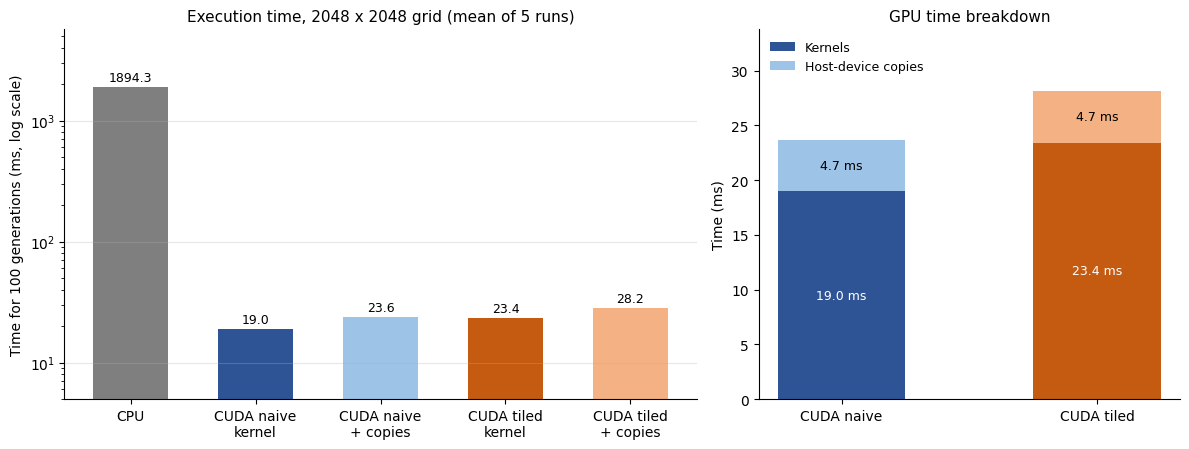

In [12]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

labels = ["CPU", "CUDA naive\nkernel", "CUDA naive\n+ copies", "CUDA tiled\nkernel", "CUDA tiled\n+ copies"]
vals   = [cpu_mean, st.mean(kern["Naive"]), st.mean(total["Naive"]), st.mean(kern["Tiled"]), st.mean(total["Tiled"])]
cols   = ["#7F7F7F", "#2F5496", "#9DC3E6", "#C55A11", "#F4B183"]
bars = ax1.bar(labels, vals, color=cols, width=0.6)
ax1.set_yscale("log")
ax1.set_ylim(5, max(vals) * 3)
ax1.set_ylabel(f"Time for {ITERS} generations (ms, log scale)")
ax1.set_title(f"Execution time, {N} x {N} grid (mean of {RUNS} runs)", fontsize=11)
for b, v in zip(bars, vals):
    ax1.text(b.get_x() + b.get_width() / 2, v * 1.12, f"{v:.1f}", ha="center", fontsize=9)
ax1.grid(axis="y", alpha=0.3)

names = ["CUDA naive", "CUDA tiled"]
km = [st.mean(kern["Naive"]), st.mean(kern["Tiled"])]
cm = [copy_ms["Naive"], copy_ms["Tiled"]]
ax2.bar(names, km, color=["#2F5496", "#C55A11"], width=0.5, label="Kernels")
ax2.bar(names, cm, bottom=km, color=["#9DC3E6", "#F4B183"], width=0.5, label="Host-device copies")
for i in range(2):
    ax2.text(i, km[i] / 2, f"{km[i]:.1f} ms", ha="center", va="center", color="white", fontsize=9)
    ax2.text(i, km[i] + cm[i] / 2, f"{cm[i]:.1f} ms", ha="center", va="center", fontsize=9)
ax2.set_ylim(0, max(a + b for a, b in zip(km, cm)) * 1.2)
ax2.set_ylabel("Time (ms)")
ax2.set_title("GPU time breakdown", fontsize=11)
ax2.legend(frameon=False, fontsize=9, loc="upper left")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("comparison.png", dpi=150)
plt.show()

## 6. Correctness verification

Runs both programs in `save` mode and checks that the final grids are identical.

In [13]:
import numpy as np

def read_pgm(path):
    """Read a binary (P5) PGM file written by the C / CUDA programs."""
    with open(path, "rb") as f:
        assert f.readline().strip() == b"P5", "not a binary PGM"
        w, h = map(int, f.readline().split())
        f.readline()
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(h, w)

run(["./life_cpu", "save"])
gpu_out = run(["./life_cuda", "save"])

cpu_grid, gpu_grid = read_pgm("frame_cpu.pgm"), read_pgm("frame_cuda.pgm")
cpu_alive, gpu_alive = int((cpu_grid > 0).sum()), int((gpu_grid > 0).sum())
cpu_hash = hashlib.sha256(cpu_grid.tobytes()).hexdigest()
gpu_hash = hashlib.sha256(gpu_grid.tobytes()).hexdigest()
diff_cells = int((cpu_grid != gpu_grid).sum())
kernels_match = "MATCH" in gpu_out

print(f"CPU live cells : {cpu_alive:,}   SHA-256 {cpu_hash[:16]}...")
print(f"GPU live cells : {gpu_alive:,}   SHA-256 {gpu_hash[:16]}...")
print(f"Cells that differ         : {diff_cells}")
print(f"Naive and tiled kernels   : {'identical' if kernels_match else 'DIFFERENT'}")
print(f"Final grids identical     : {diff_cells == 0}")

CPU live cells : 401,781   SHA-256 c360510d69799c7d...
GPU live cells : 401,781   SHA-256 c360510d69799c7d...
Cells that differ         : 0
Naive and tiled kernels   : identical
Final grids identical     : True


## 7. Animation

Saves frames from both programs, checks they match, and builds the GIFs.

In [14]:
for d in ("frames_cpu", "frames_cuda"):
    if os.path.isdir(d):
        for f in glob.glob(f"{d}/*.pgm"):
            os.remove(f)                                  # remove frames from earlier runs

run(["./life_cpu", "frames", str(FRAME_EVERY)])
run(["./life_cuda", "frames", str(FRAME_EVERY)])

names = sorted(os.path.basename(f) for f in glob.glob("frames_cpu/frame_*.pgm"))
same = [n for n in names if filecmp.cmp(f"frames_cpu/{n}", f"frames_cuda/{n}", shallow=False)]
frames_ok = len(names) > 0 and len(same) == len(names) == len(glob.glob("frames_cuda/frame_*.pgm"))
print(f"{len(same)} of {len(names)} frame pairs identical")

print("\nLive cells inside the 256 x 256 corner:")
print(f"{'generation':>12}{'CPU':>10}{'GPU':>10}")
for n in names[::5]:
    gen = int(n[6:10])
    c = int((read_pgm(f"frames_cpu/{n}") > 0).sum())
    g = int((read_pgm(f"frames_cuda/{n}") > 0).sum())
    print(f"{gen:>12}{c:>10}{g:>10}")

51 of 51 frame pairs identical

Live cells inside the 256 x 256 corner:
  generation       CPU       GPU
           0     19696     19696
          10     14076     14076
          20     11172     11172
          30      9742      9742
          40      8626      8626
          50      8192      8192
          60      7795      7795
          70      7568      7568
          80      7256      7256
          90      6785      6785
         100      6643      6643


51 frames per GIF: life_cpu.gif, life_cuda.gif, life_cpu_vs_cuda.gif
Left: CPU   Right: GPU


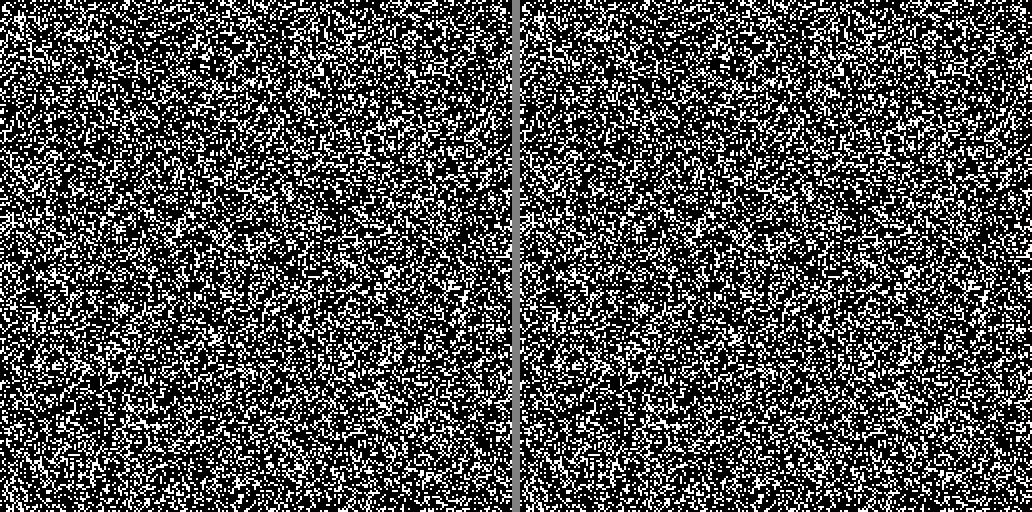

In [15]:
from PIL import Image
from IPython.display import Image as IPImage, display

GAP = 8
cpu_f, gpu_f, pair_f = [], [], []
for n in names:
    c = Image.open(f"frames_cpu/{n}").resize((GIF_SIZE, GIF_SIZE), Image.NEAREST)    # NEAREST keeps cells sharp
    g = Image.open(f"frames_cuda/{n}").resize((GIF_SIZE, GIF_SIZE), Image.NEAREST)
    both = Image.new("L", (2 * GIF_SIZE + GAP, GIF_SIZE), 128)
    both.paste(c, (0, 0)); both.paste(g, (GIF_SIZE + GAP, 0))
    cpu_f.append(c); gpu_f.append(g); pair_f.append(both)

def save_gif(path, fr):
    fr[0].save(path, save_all=True, append_images=fr[1:], duration=GIF_MS, loop=0, optimize=True)

save_gif("life_cpu.gif", cpu_f)
save_gif("life_cuda.gif", gpu_f)
save_gif("life_cpu_vs_cuda.gif", pair_f)
print(f"{len(names)} frames per GIF: life_cpu.gif, life_cuda.gif, life_cpu_vs_cuda.gif")
print("Left: CPU   Right: GPU")
display(IPImage("life_cpu_vs_cuda.gif"))

## 8. Summary and output files

Prints the final summary and saves `results_summary.json`.

In [16]:
summary = {
    "environment": {"cpu": cpu_model, "gpu": gpu_name, "compute_capability": gpu_cc,
                    "driver": gpu_driver, "cuda": nvcc_ver, "nvcc_arch": ARCH,
                    "cpu_build": f"gcc {CPU_FLAGS}"},
    "setup": {"grid": f"{N}x{N}", "generations": ITERS, "runs": RUNS, "warmup_launches": WARMUP},
    "cpu_ms": {"mean": cpu_mean, "min": min(cpu_runs), "max": max(cpu_runs)},
    "gpu_ms": {key.lower(): {"kernel_mean": st.mean(kern[key]), "total_mean": st.mean(total[key]),
                             "kernel_min": min(kern[key]), "kernel_max": max(kern[key])}
               for key in ("Naive", "Tiled")},
    "speedup": {key.lower(): {"kernel": cpu_mean / st.mean(kern[key]), "total": cpu_mean / st.mean(total[key])}
                for key in ("Naive", "Tiled")},
    "verification": {"cpu_live_cells": cpu_alive, "gpu_live_cells": gpu_alive,
                     "differing_cells": diff_cells, "kernels_identical": kernels_match,
                     "final_grids_identical": diff_cells == 0,
                     "frame_pairs_identical": f"{len(same)}/{len(names)}"},
}
with open("results_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(f"GPU : {gpu_name} ({ARCH})    CPU : {cpu_model}")
print(f"CPU : {cpu_mean:8.1f} ms")
for key in ("Naive", "Tiled"):
    s = summary["speedup"][key.lower()]
    print(f"{key:<5}: kernel {st.mean(kern[key]):6.2f} ms, total {st.mean(total[key]):6.2f} ms"
          f"  ->  {s['kernel']:.1f}x kernel, {s['total']:.1f}x with copies")
ok = diff_cells == 0 and kernels_match and frames_ok
print(f"\nVerification: {'PASSED' if ok else 'FAILED'} "
      f"(final grids identical: {diff_cells == 0}, kernels identical: {kernels_match}, "
      f"frames identical: {len(same)}/{len(names)})")

print("\nOutput files:")
for p in ["benchmark_runs.csv", "comparison.png", "frame_cpu.pgm", "frame_cuda.pgm",
          "life_cpu.gif", "life_cuda.gif", "life_cpu_vs_cuda.gif", "results_summary.json"]:
    print(f"  {p:<26}{os.path.getsize(p) / 1024:>10.1f} KB")
print(f"  frames_cpu/, frames_cuda/  {len(names)} frames each")

GPU : Tesla T4 (sm_75)    CPU : Intel(R) Xeon(R) CPU @ 2.00GHz
CPU :   1894.3 ms
Naive: kernel  18.97 ms, total  23.64 ms  ->  99.9x kernel, 80.1x with copies
Tiled: kernel  23.44 ms, total  28.15 ms  ->  80.8x kernel, 67.3x with copies

Verification: PASSED (final grids identical: True, kernels identical: True, frames identical: 51/51)

Output files:
  benchmark_runs.csv               0.4 KB
  comparison.png                  64.6 KB
  frame_cpu.pgm                 4096.0 KB
  frame_cuda.pgm                4096.0 KB
  life_cpu.gif                   922.6 KB
  life_cuda.gif                  922.6 KB
  life_cpu_vs_cuda.gif          1831.5 KB
  results_summary.json             1.2 KB
  frames_cpu/, frames_cuda/  51 frames each
